In [497]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np 
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

خب در ابتدا یک برسی کلی روی داده ها داشتیم 
داده ها گرچه مقادیر پرت خیلی ناچیزی دارند و مقادیر گمشده هم توی داده ها وجود نداره ولی مقدار محدودی داده داریم 
5 ستون و 200 سطر
که از دو ستون جنسیت و شناسه مشتری هم نمیشه استفاده کرد 
و مشخصه های ما 3 ستون سن ، درآمد و امتیاز کاربر هست 
البته در ابتدا سن رو هم لحاظ کرده بودم و یک نمودار 3 بعدی هم برای داده ها ترسیم کردم اما با حذف سن 
توی هر دوتا مدل نتیجه بهتری رو کسب کردم 
کد های مربوط به نمودار کامنت شده 

In [554]:
df = pd.read_csv('1632560262896716.csv')
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [555]:
df = df.drop(columns=['CustomerID', 'Gender', 'Age'])

In [556]:
df.isnull().sum()

Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

{'whiskers': [<matplotlib.lines.Line2D at 0x1aaa3ad1d10>,
 'caps': [<matplotlib.lines.Line2D at 0x1aaa3ad1f90>,
 'boxes': [<matplotlib.lines.Line2D at 0x1aaa3ad1bd0>,
 'medians': [<matplotlib.lines.Line2D at 0x1aaa3ad2210>,
 'fliers': [<matplotlib.lines.Line2D at 0x1aaa3ad2350>,
 'means': []}

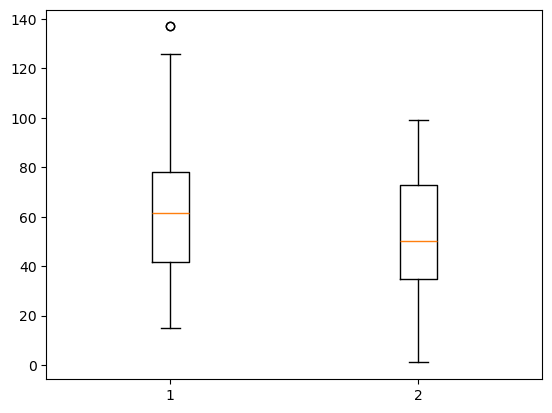

In [557]:
plt.boxplot(df[['Annual Income (k$)', 'Spending Score (1-100)']])

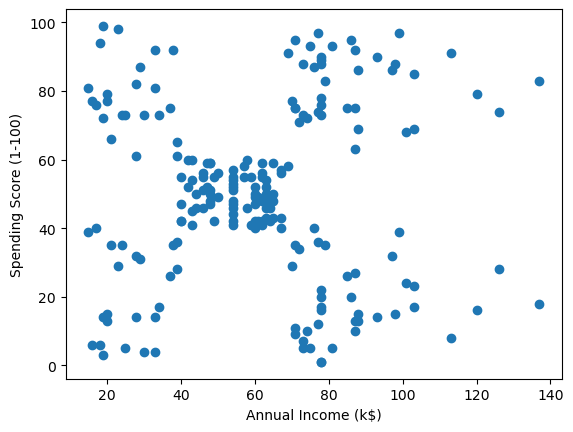

In [558]:
x = df['Annual Income (k$)']
y = df["Spending Score (1-100)"]

plt.scatter(x, y)
plt.xlabel('Annual Income (k$)')
plt.ylabel("Spending Score (1-100)")
plt.show()

In [559]:
# import matplotlib.pyplot as plt

# fig = plt.figure(figsize=(10, 7))
# ax = fig.add_subplot(111, projection="3d")

# ax.scatter(
#     df["Age"],
#     df["Annual Income (k$)"],
#     df["Spending Score (1-100)"],
#     alpha=0.6
# )

# ax.set_xlabel("Age")
# ax.set_ylabel("Annual Income (k$)")
# ax.set_zlabel("Spending Score (1-100)")
# ax.set_title("3D Data Visualization")

# plt.show()

In [560]:
# df["Gender"] = df["Gender"].map({
#     'Male': 1,
#     'Female': 0,
# })
# df

In [561]:
# استاندارد سازی داده ها
X = df
Scaler = StandardScaler()
X_scaled = Scaler.fit_transform(X)
X_scaled

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002],
       [-1.58632148, -1.4053405 ],
       [-1.58632148,  1.89449216],
       [-1.54815205, -1.36651894],
       [-1.54815205,  1.04041783],
       [-1.54815205, -1.44416206],
       [-1.54815205,  1.11806095],
       [-1.50998262, -0.59008772],
       [-1.50998262,  0.61338066],
       [-1.43364376, -0.82301709],
       [-1.43364376,  1.8556706 ],
       [-1.39547433, -0.59008772],
       [-1.39547433,  0.88513158],
       [-1.3573049 , -1.75473454],
       [-1.3573049 ,  0.88513158],
       [-1.24279661, -1.4053405 ],
       [-1.24279661,  1.23452563],
       [-1.24279661, -0.7065524 ],
       [-1.24279661,  0.41927286],
       [-1.20462718,

In [562]:
# ایجاد یک حلقه برای برسی اینکه بهترینن تعداد خوشه ها چه عددی میباشد 
score = 0
for n in range(2, 12):
    kmeans = KMeans(init='k-means++', n_clusters=n, random_state=42, n_init="auto")
    kmeans.fit(X_scaled)
    labels = kmeans.labels_
    if silhouette_score(X_scaled, labels) > score:
        score = silhouette_score(X_scaled, labels)
        print(n)

2
3
4
5


C:\Users\Arab\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Arab\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Arab\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Arab\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows wi

In [563]:
# labels = kmeans.labels_

In [564]:
import pandas as pd

print(pd.Series(labels).value_counts().sort_index())

0     49
1     11
2     11
3     20
4     12
5     25
6     31
7      8
8     11
9      3
10    19
Name: count, dtype: int64


In [565]:
# import matplotlib.pyplot as plt

# fig = plt.figure(figsize=(10, 7))
# ax = fig.add_subplot(111, projection="3d")

# scatter = ax.scatter(
#     X["Age"],
#     X["Annual Income (k$)"],
#     X["Spending Score (1-100)"],
#     c=labels,
#     cmap="viridis",
#     s=50,
#     alpha=0.8
# )

# ax.set_xlabel("Age")
# ax.set_ylabel("Annual Income (k$)")
# ax.set_zlabel("Spending Score (1-100)")
# ax.set_title("K-Means Clustering (4 Clusters)")

# fig.colorbar(scatter, ax=ax, label="Cluster")
# plt.show()

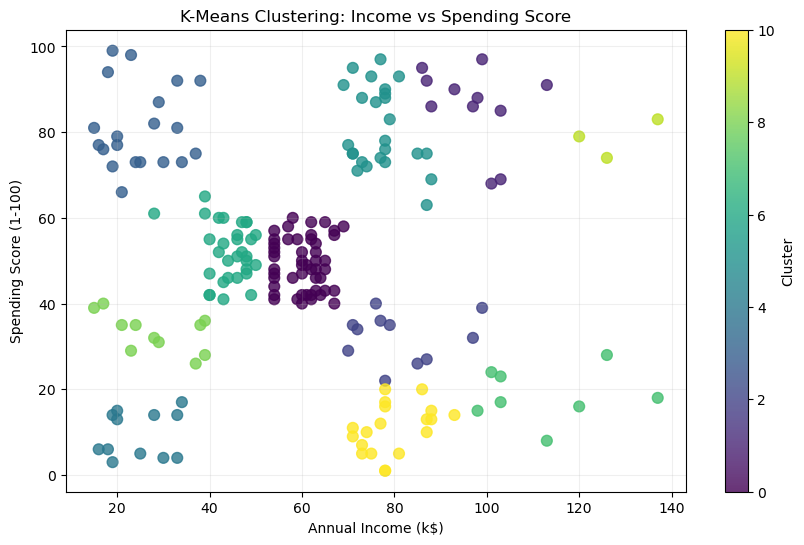

In [566]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"],
    c=labels,
    cmap="viridis",
    s=60,
    alpha=0.8
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Clustering: Income vs Spending Score")
plt.colorbar(label="Cluster")
plt.grid(alpha=0.2)
plt.show()

In [567]:
"""از معیار Silhouette
برای برسی دقت مدل استفاده کردم"""
score = silhouette_score(X_scaled, labels)
print("Score:", score)

Silhouette Score: 0.4456479428438176


In [568]:
# این هم کد مربوط به مدل سازی DBSCAN 
db = DBSCAN(eps=0.4, min_samples=8).fit(X_scaled)
labels_db = db.labels_

mask = labels_db != -1


X_clean = X_scaled[mask]

labels_clean = labels_db[mask]

dbscore = davies_bouldin_score(X_clean, labels_clean)

print(dbscore)

0.5014647059705599


In [569]:
n_clusters = len(set(labels_db) - {-1})
n_noise = np.sum(labels_db == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Noise percentage:", round(100 * n_noise / len(labels_db), 2), "%")

Number of clusters: 5
Number of noise points: 25
Noise percentage: 12.5 %


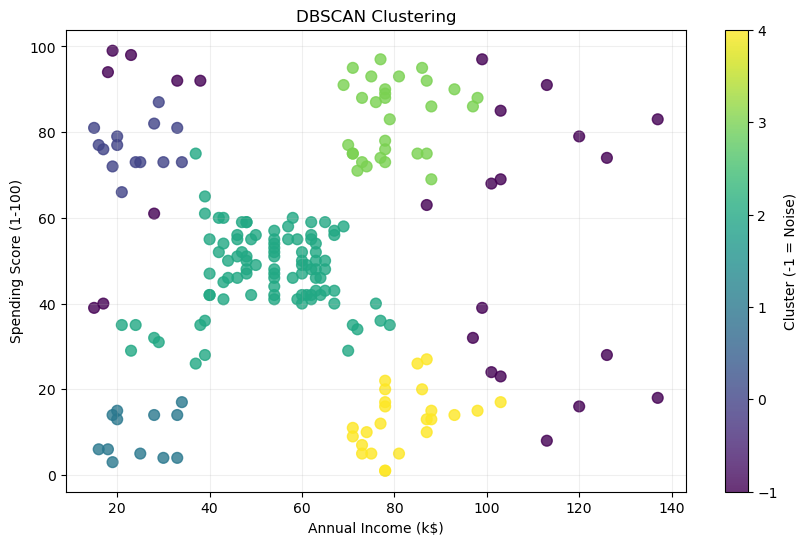

In [570]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"],
    c=labels_db,
    cmap="viridis",
    s=60,
    alpha=0.8
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("DBSCAN Clustering")
plt.colorbar(label="Cluster (-1 = Noise)")
plt.grid(alpha=0.2)
plt.show()

جمعع بندی: 
با این حجم داده شاید بشه محطاتانه نظر داد که مدل DBSCAN 
انتخاب بهتری بوده و تقسیم داده ها دقیق تر انجام شده 
البته که هر دو مدل امتیاز بالایی به خودشون اختصاص ندادند

In [494]:
for y in range(15, -15, -1):
    for x in range(-30, 30):
        a = (x * 0.04)**2 + (y * 0.1)**2 - 1
        if a**3 - (x * 0.04)**2 * (y * 0.1)**3 <= 0:
            print("*", end="")
        else:
            print(" ", end="")
    print()

                                                            
                                                            
                                                            
            ***********               ***********           
        ********************     ********************       
     ***************************************************    
    *****************************************************   
   *******************************************************  
  ********************************************************* 
  ********************************************************* 
  ********************************************************* 
  ********************************************************* 
   *******************************************************  
   *******************************************************  
    *****************************************************   
     ***************************************************    
       *****************

اینم یک قلبه گنده برای منتور خوب و مشتی مکتب خونه 
ممنون که توی این روزای سخت پروژه های منو صحیح میکنی و توی این مسیر همراه منی 
سپاس از شما